# Odor vs vision: is either cue used to find the target?

Puts the results of `odor_search_strategy.ipynb` (cbm-odor) and `vision_search_strategy.ipynb` (cbm-vision) side by side. The task, the arena and the nine mice are the same; what differs is the cue that marks the target's end of the arena on `flip_state` 0 and 1 - an odor delivered at that end, or a stimulus on the monitor at that end. `flip_state` 2 is the no-cue condition in both.

Every measure is defined exactly as in the two source notebooks:

- **Direction** - from the neutral middle row, which end is entered first? *Discrimination* = P(low first | flip 0) - P(low first | flip 1), within mouse x previous-target-end. 0 = cue side ignored, 1 = perfect.
- **Persistence and search cost** - cue trials minus no-cue trials with the same target cell and start zone, within mouse. Negative = better with the cue.

Odor is the `x` sessions (1% pinene) and vision the `v` sessions. All nine mice ran both, so the two are also compared within mouse (section 4). Each mouse contributes its first ten sessions of each experiment (x1 onward for odor; mouse 9000 ran only six vision sessions). The `o` and `t` shaping sessions of cbm-odor are left out.

**Two things that differ besides the modality.** Every mouse ran its vision sessions after all of its odor sessions, so modality is confounded with experience on the task. And the odor goes off when the target is found, while the visual stimulus stays on through the ITI until the next trial starts.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats as sps

from src import config as cfg
from src.trials import load_trials          # run `python -m src.trials` to rebuild both trial tables
from src.stats import stratified_diff, per_mouse, summarize

pd.set_option('display.width', 200, 'display.precision', 3)

SESSION_TYPES = ['x', 'v']
TYPE_COLOR = {'x': '#2a78d6', 'v': '#7a52c7'}
TYPE_LABEL = {'x': "odor 'x'", 'v': "vision 'v'"}
INK, MUTED, GRID = '#0b0b0b', '#52514e', '#e4e3df'
plt.rcParams.update({
    'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb', 'savefig.facecolor': '#fcfcfb',
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': MUTED,
    'axes.labelcolor': MUTED, 'xtick.color': MUTED, 'ytick.color': MUTED, 'text.color': INK,
    'axes.titlesize': 10, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.labelsize': 9, 'xtick.labelsize': 8, 'ytick.labelsize': 8, 'legend.fontsize': 8,
    'legend.frameon': False, 'figure.dpi': 110,
})

t = pd.concat([load_trials(e).assign(experiment=e) for e in ('odor', 'vision')], ignore_index=True)

## 1. Data

In [2]:
overview = t.groupby('session_type').agg(
    experiment=('experiment', 'first'), mice=('mouse', 'nunique'),
    sessions=('session', lambda s: t.loc[s.index].groupby(['mouse', 'session']).ngroups),
    trials=('trial', 'size'), median_search_s=('search_s', 'median'), median_path_px=('path_px', 'median'))
overview.join(pd.crosstab(t.session_type, t.flip).add_prefix('n_flip')).loc[SESSION_TYPES]

,experiment,mice,sessions,trials,median_search_s,median_path_px,n_flip0,n_flip1,n_flip2
session_type,,,,,,,,,
x,odor,9,90,10621,7.268,3741.701,3529,3549,3543
v,vision,9,86,12129,6.041,3258.591,4048,4059,4022


## 2. Is the behavior the cue acts on the same in both experiments?

Before comparing cue effects, compare what the mice do when there is nothing to use: how long the no-cue search is, how often they abandon the correct end on no-cue trials, and the two habits (favoring one end, being back at the previous target's end when a trial starts). Per mouse, `x` against `v`.

In [3]:
def by_mouse(d, f):
    cols = ['log2_path_px', 'left_after_reach', 'start_zone', 'prev_target_zone']
    return d.groupby(['mouse', 'session_type'])[cols].apply(f).unstack()

def paired(m, a='x', b='v'):
    """Across-mouse summary of b - a for a mouse x session-type table."""
    d = m[[a, b]].dropna()
    diff = d[b] - d[a]
    lo, hi = sps.t.interval(0.95, len(d) - 1, diff.mean(), sps.sem(diff))
    return pd.Series({f'{a} mean': d[a].mean(), f'{b} mean': d[b].mean(), f'{b} - {a}': diff.mean(), 'ci_lo': lo, 'ci_hi': hi,
                      'p (paired t)': sps.ttest_rel(d[b], d[a]).pvalue, f'mice {b} < {a}': f'{int((diff < 0).sum())}/{len(d)}'})

nocue = t[~t.cue & (t.search_s <= cfg.MAX_SEARCH_S)]
prev = t[t.prev_target_zone.isin(['low', 'high'])]
BASELINE = {
    'no-cue search path (log2 px)': by_mouse(nocue, lambda d: d.log2_path_px.mean()),
    'no-cue P(left correct end)': by_mouse(nocue, lambda d: d.left_after_reach.mean()),
    'side bias:\nP(start low) - P(start high)': by_mouse(t, lambda d: (d.start_zone == 'low').mean() - (d.start_zone == 'high').mean()),
    "return to previous target:\nP(start at its end) - P(other end)": by_mouse(prev, lambda d: (
        (d.start_zone == d.prev_target_zone).mean() - ((d.start_zone != d.prev_target_zone) & (d.start_zone != 'mid')).mean())),
}
pd.DataFrame({name.replace('\n', ' '): paired(m) for name, m in BASELINE.items()}).T

,x mean,v mean,v - x,ci_lo,ci_hi,p (paired t),mice v < x
no-cue search path (log2 px),11.703,11.433,-0.27,-0.414,-0.126,0.003,9/9
no-cue P(left correct end),0.464,0.41,-0.054,-0.094,-0.014,0.014,8/9
side bias: P(start low) - P(start high),0.088,0.073,-0.015,-0.049,0.019,0.35,7/9
return to previous target: P(start at its end) - P(other end),0.115,0.128,0.013,-0.074,0.101,0.731,3/9


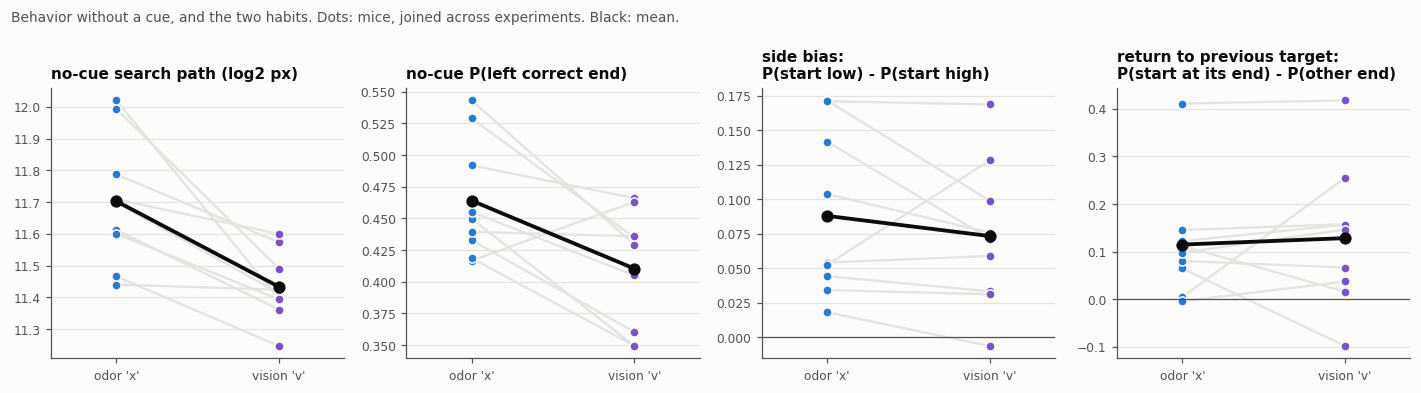

In [4]:
def paired_dots(ax, m, title, a='x', b='v', zero=False):
    d = m[[a, b]].dropna()
    for mouse in d.index:
        ax.plot([0, 1], d.loc[mouse], color=GRID, lw=1.5, zorder=1)
    for i, st in enumerate((a, b)):
        ax.scatter(np.full(len(d), i), d[st], s=36, color=TYPE_COLOR[st], zorder=2, edgecolor='#fcfcfb', lw=1)
    ax.plot([0, 1], d.mean(), color=INK, lw=2.5, marker='o', ms=7, zorder=3)
    if zero:
        ax.axhline(0, color=MUTED, lw=0.8)
    ax.set(xticks=[0, 1], xticklabels=[TYPE_LABEL[a], TYPE_LABEL[b]], xlim=(-0.4, 1.4), title=title)
    ax.yaxis.grid(True, color=GRID); ax.set_axisbelow(True)

fig, axes = plt.subplots(1, len(BASELINE), figsize=(13, 3.6))
for ax, (name, m) in zip(axes, BASELINE.items()):
    paired_dots(ax, m, name, zero='P(start' in name)
fig.suptitle('Behavior without a cue, and the two habits. Dots: mice, joined across experiments. Black: mean.',
             x=0.01, ha='left', fontsize=9, color=MUTED)
plt.tight_layout(); plt.show()

The habits are the same in the two experiments, but the mice search more efficiently in the vision sessions even when no cue is present: no-cue paths are about 17% shorter (log2 -0.27, 9/9 mice) and they abandon the correct end less often (41% against 46%, 8/9 mice). Vision came second, so this is most simply more practice at the task.

It matters for the comparison: cue trials are also shorter in `v` than in `x` (about 10%, 7/9 mice), for the same reason, so comparing cue trials directly across experiments would credit the visual stimulus with an improvement that is there without it. Everything below therefore compares each cue to the no-cue trials of its own sessions.

## 3. Cue effects in each experiment

The direction measure and the five matched cue-vs-no-cue measures, each tested against zero. The first panel is the only one where up is good; in the others a mouse using the cue sits below zero.

In [5]:
mid = t[(t.start_zone == 'mid') & (t.first_entry != 'none')].copy()
mid['low_first'] = (mid.first_entry == 'low').astype(float)
mid['is_flip0'] = mid.flip == 0
cost = t[(t.geometry != 'target in middle') & (t.search_s <= cfg.MAX_SEARCH_S)]

MATCH = ['target_cell', 'start_zone']
METRICS = {   # name: (column, which trials)
    'whole search path (log2)':      ('log2_path_px',       ['same end', 'opposite end', 'from middle']),
    'approach path (log2)':          ('log2_reach_path_px', ['opposite end', 'from middle']),
    'P(wrong end first)':            ('wrong_end_first',    ['from middle']),
    'local search path (log2)':      ('log2_local_path_px', ['same end', 'opposite end', 'from middle']),
    'P(left correct end)':           ('left_after_reach',   ['same end', 'opposite end', 'from middle']),
}

def measures(st):
    """{name: (trials, outcome, label, strata)} for one session type - the arguments summarize / per_mouse take."""
    out = {'direction: discrimination': (mid[(mid.session_type == st) & mid.cue], 'low_first', 'is_flip0', ['prev_target_zone'])}
    for name, (col, geoms) in METRICS.items():
        out[name] = (cost[(cost.session_type == st) & cost.geometry.isin(geoms)], col, 'cue', MATCH)
    return out

MEASURES = list(measures('x'))
effects = pd.DataFrame({(name, st): summarize(*args) for st in SESSION_TYPES for name, args in measures(st).items()}).T
effects = effects.loc[[(name, st) for name in MEASURES for st in SESSION_TYPES]]
mouse_fx = {name: pd.DataFrame({st: per_mouse(*measures(st)[name]) for st in SESSION_TYPES}) for name in MEASURES}
effects

effect p_perm mouse_mean  ci_lo  ci_hi mice_same_sign n_trials
direction: discrimination x -0.003  0.925     -0.022 -0.153  0.108            3/9     1069
                          v -0.001  0.967     -0.007 -0.062  0.048            5/9     1139
whole search path (log2)  x -0.117  0.007     -0.115  -0.24  0.009            7/9    10043
                          v -0.012  0.754     -0.008 -0.096   0.08            3/9    11532
approach path (log2)      x  -0.11  0.006     -0.109 -0.224  0.006            7/9     5817
                          v  0.036  0.334       0.03 -0.035  0.094            5/9     6532
P(wrong end first)        x -0.044  0.149     -0.037 -0.119  0.044            6/9     1491
                          v  0.022  0.459       0.02 -0.065  0.105            5/9     1586
local search path (log2)  x -0.085  0.093     -0.079 -0.223  0.064            7/9    10043
                          v -0.029  0.519     -0.025 -0.126  0.077            5/9    11532
P(left correct end)       x -0.034  0.003     -0.033 -0.057 -0.009            7/9    10043
                          v  0.003  0.726      0.005  -0.02   0.03            6/9    11532

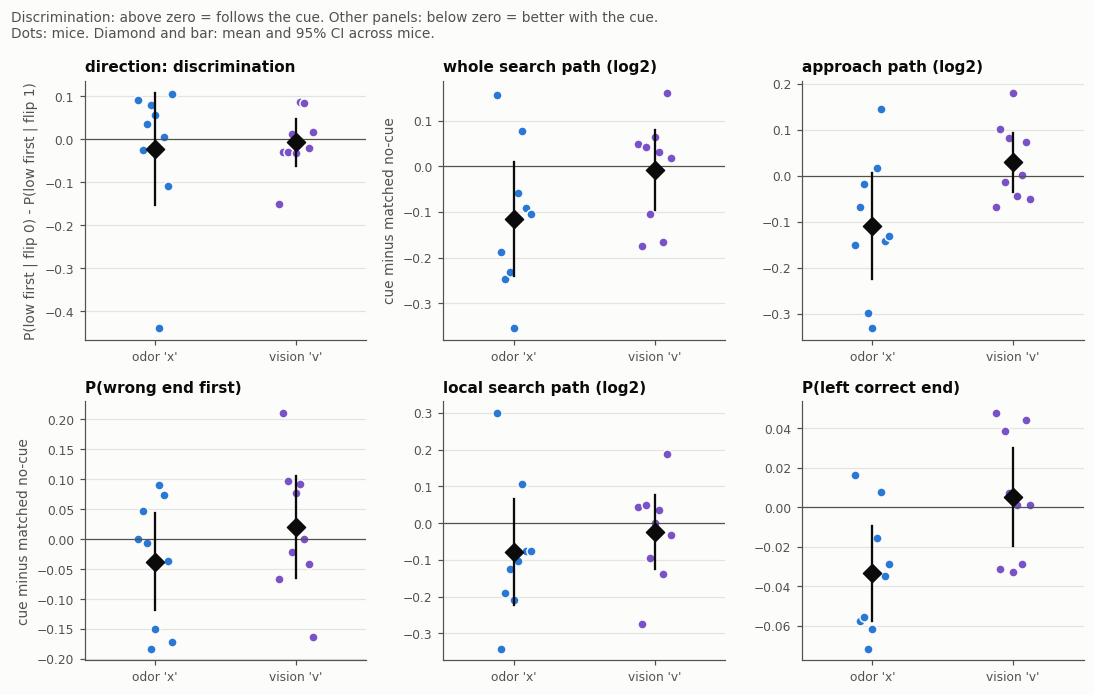

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(10, 6.4))
for ax, name in zip(axes.flat, MEASURES):
    for i, st in enumerate(SESSION_TYPES):
        pm = mouse_fx[name][st].dropna()
        ax.scatter(i + np.linspace(-0.12, 0.12, len(pm)), pm, s=36, color=TYPE_COLOR[st], edgecolor='#fcfcfb', lw=1, zorder=2)
        r = effects.loc[(name, st)]
        ax.plot([i, i], [r.ci_lo, r.ci_hi], color=INK, lw=1.5, zorder=3)
        ax.scatter([i], [r.mouse_mean], s=70, color=INK, marker='D', zorder=4)
    ax.axhline(0, color=MUTED, lw=0.8)
    ax.set(xticks=range(len(SESSION_TYPES)), xticklabels=[TYPE_LABEL[s] for s in SESSION_TYPES],
           xlim=(-0.5, len(SESSION_TYPES) - 0.5), title=name)
    ax.yaxis.grid(True, color=GRID); ax.set_axisbelow(True)
axes[0, 0].set_ylabel('P(low first | flip 0) - P(low first | flip 1)')
axes[0, 1].set_ylabel('cue minus matched no-cue')
axes[1, 0].set_ylabel('cue minus matched no-cue')
fig.suptitle('Discrimination: above zero = follows the cue. Other panels: below zero = better with the cue.\n'
             'Dots: mice. Diamond and bar: mean and 95% CI across mice.', x=0.01, ha='left', fontsize=9, color=MUTED)
plt.tight_layout(); plt.show()

## 4. Odor `x` vs vision `v`, within mouse

The same per-mouse effects, paired: each mouse's `v` effect minus its `x` effect. This asks whether the two cues differ from *each other*, which the separate tests against zero above do not answer.

In [7]:
within = pd.DataFrame({name: paired(mouse_fx[name]) for name in MEASURES}).T
within

,x mean,v mean,v - x,ci_lo,ci_hi,p (paired t),mice v < x
direction: discrimination,-0.022,-0.007,0.015,-0.151,0.181,0.836,6/9
whole search path (log2),-0.115,-0.008,0.107,-0.049,0.264,0.153,2/9
approach path (log2),-0.109,0.03,0.138,-0.022,0.299,0.082,2/9
P(wrong end first),-0.037,0.02,0.058,-0.026,0.141,0.152,3/9
local search path (log2),-0.079,-0.025,0.055,-0.093,0.203,0.419,2/9
P(left correct end),-0.033,0.005,0.039,0.008,0.069,0.02,1/9


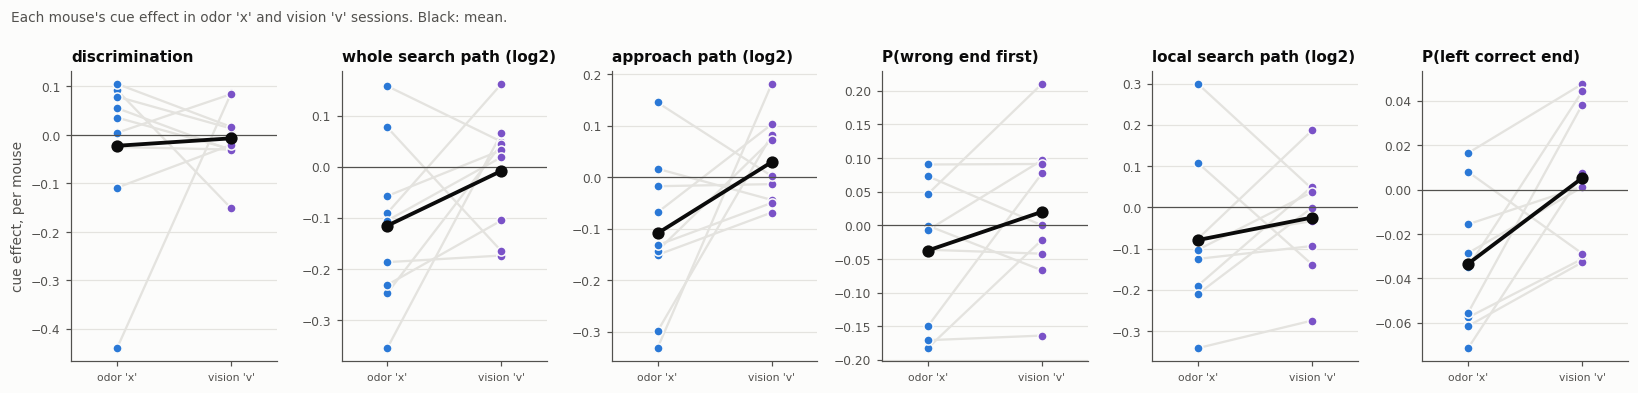

In [8]:
fig, axes = plt.subplots(1, len(MEASURES), figsize=(15, 3.6))
for ax, name in zip(axes, MEASURES):
    paired_dots(ax, mouse_fx[name], name.replace('direction: ', ''), zero=True)
    ax.tick_params(axis='x', labelsize=7)
axes[0].set_ylabel('cue effect, per mouse')
fig.suptitle("Each mouse's cue effect in odor 'x' and vision 'v' sessions. Black: mean.", x=0.01, ha='left', fontsize=9, color=MUTED)
plt.tight_layout(); plt.show()

## 5. Across sessions

Both headline measures by how many sessions the mouse has had (its 1st to 10th), pooling mice. Vision sessions came after the odor sessions for every mouse, so the `v` line continues each mouse's history rather than restarting it.

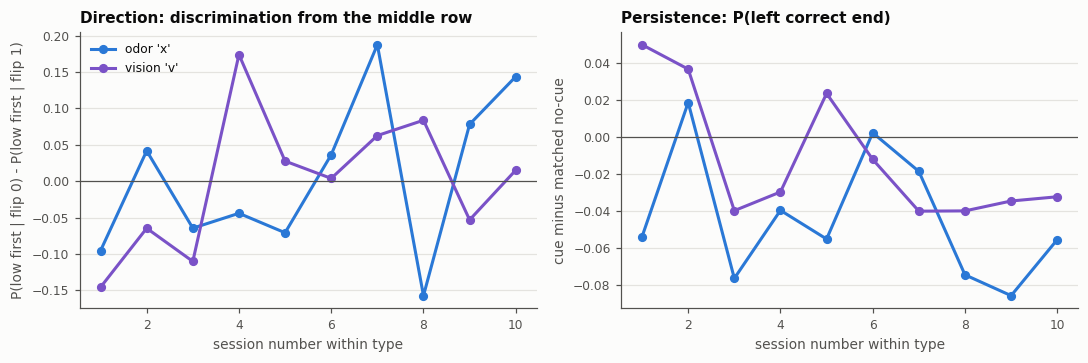

In [9]:
def by_session(d, y, label, keys, min_trials):
    out = d.groupby(['session_type', 'session_num'])[[y, label] + keys].apply(
        lambda g: pd.Series({'effect': stratified_diff(g, y, label, keys), 'n': len(g)}))
    return out[out.n >= min_trials]

disc = by_session(mid[mid.cue], 'low_first', 'is_flip0', ['mouse'], 30)
pers = by_session(cost, 'left_after_reach', 'cue', ['mouse', 'target_zone', 'start_zone'], 150)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
for ax, data, title, ylabel in ((axes[0], disc, 'Direction: discrimination from the middle row', 'P(low first | flip 0) - P(low first | flip 1)'),
                                (axes[1], pers, 'Persistence: P(left correct end)', 'cue minus matched no-cue')):
    for st in SESSION_TYPES:
        s = data.loc[st].effect
        ax.plot(s.index, s.values, color=TYPE_COLOR[st], lw=2, marker='o', ms=5, label=TYPE_LABEL[st])
    ax.axhline(0, color=MUTED, lw=0.8)
    ax.set(title=title, ylabel=ylabel, xlabel='session number within type')
    ax.yaxis.grid(True, color=GRID); ax.set_axisbelow(True)
axes[0].legend()
plt.tight_layout(); plt.show()

## Summary

**Neither cue tells the mice which end to go to, and only the odor changes the search at all - slightly.**

**Direction.** Discrimination from the middle row is 0.00 in odor `x` sessions (95% CI across mice -0.15 to 0.11) and 0.00 in vision `v` sessions (-0.06 to 0.05). Within mouse the two differ by 0.02 (CI -0.15 to 0.18).

**Persistence and search cost.**
- Odor `x`: with the odor on, the search path is about 8% shorter than on matched no-odor trials (log2 -0.12, p = 0.007) and mice leave the correct end on 3.4 percentage points fewer trials (p = 0.003), 7/9 mice each.
- Vision `v`: nothing. Path log2 -0.01 (p = 0.75), P(left correct end) +0.3 points (p = 0.73).
- Within mouse, the odor's effect on P(left correct end) is larger than the stimulus's in 8 of 9 mice (difference 3.9 points, CI 0.8 to 6.9, paired p = 0.020). The path measures point the same way (7/9 mice) but are not reliable (p = 0.08 to 0.42).

**How strong is the evidence that the cues differ?** Moderate. The one paired test that reaches p < 0.05 is unadjusted across six and would not survive a Bonferroni correction (threshold 0.008). What supports it is consistency: the odor effect in `x` survives correction on its own, the vision estimate is centered on zero with a narrow interval, and the sign of the difference is the same in nearly every mouse.

**What the comparison cannot separate.**
- *Modality from experience.* Every mouse ran vision after odor, and by then searched about 17% more efficiently without any cue (section 2). A mouse with a better cue-free strategy may have less to gain from a weak cue, so a smaller cue effect in `v` is not purely a statement about vision.
- *Modality from timing.* The odor goes off at the target; the visual stimulus stays on through the ITI and changes only at the next trial start.
- *The odor from what accompanies it.* As noted in the odor notebook, the `x` effect could come from anything that coincides with odor delivery (valve sound, airflow). The visual stimulus has no such accompaniment, which fits that reading as well as it fits a real odor effect.

**No learning in either.** Neither measure trends consistently across the ten sessions in `x` or in `v`.

**Bottom line.** In neither modality are mice solving the task as designed. From the middle row they pick the cued end at chance, and once at the correct end they leave it before finding the target on more than 40% of trials whether or not a cue is present.